In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression

import warnings
warnings.filterwarnings("ignore")

cancer = load_breast_cancer()

In [8]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

scaler = StandardScaler()
data_scaled = scaler.fit_transform(cancer.data)

X_train, X_test, y_train, y_test = train_test_split(data_scaled,
                cancer.target, test_size = 0.3, random_state = 42)

In [9]:
from sklearn.metrics import accuracy_score, roc_auc_score

lr_clf = LogisticRegression() # solver = "lbfgs"
lr_clf.fit(X_train, y_train)
lr_pred = lr_clf.predict(X_test)
lr_pred_proba = lr_clf.predict_proba(X_test)[:, 1]

print(accuracy_score(y_test, lr_pred), roc_auc_score(y_test, lr_pred_proba))

0.9824561403508771 0.9980893592004703


In [10]:
solvers = ["lbfgs", "liblinear", "newton-cg", "sag", "saga"]

for solver in solvers:
    lr_clf = LogisticRegression(solver = solver, max_iter = 600)
    lr_clf.fit(X_train, y_train)
    lr_pred = lr_clf.predict(X_test)
    lr_pred_proba = lr_clf.predict_proba(X_test)[:, 1]
    print(solver, accuracy_score(y_test, lr_pred),
          roc_auc_score(y_test, lr_pred_proba))

lbfgs 0.9824561403508771 0.9980893592004703
liblinear 0.9824561403508771 0.9980893592004703
newton-cg 0.9824561403508771 0.9980893592004703
sag 0.9824561403508771 0.9980893592004703
saga 0.9824561403508771 0.9980893592004703


In [11]:
from sklearn.model_selection import GridSearchCV

params = {"solver": ["liblinear", "lbfgs"],
          "l1_ratio": [0, 1],
          "C": [0.01, 0.1, 1, 5, 10]}
lr_clf = LogisticRegression()

grid_clf = GridSearchCV(lr_clf, param_grid = params, scoring = "accuracy", cv = 3)
grid_clf.fit(data_scaled, cancer.target)
print(grid_clf.best_params_, grid_clf.best_score_)

{'C': 0.1, 'l1_ratio': 0, 'solver': 'liblinear'} 0.9789102385593614


In [12]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestRegressor
import pandas as pd
import numpy as np

In [16]:
housing = fetch_california_housing()
df = pd.DataFrame(housing.data, columns = housing.feature_names)

df["PRICE"] = housing.target
y_target = df["PRICE"]
X_data = df.drop(["PRICE"], axis = 1, inplace = False)

rf = RandomForestRegressor(random_state = 0, n_estimators = 1000,
                           n_jobs = -1)
neg_mse_scores = cross_val_score(rf, X_data, y_target,
            scoring = "neg_mean_squared_error", cv = 5)
rmse_scores = np.sqrt(-1 * neg_mse_scores)
avg_rmse = np.mean(rmse_scores)

print(np.round(neg_mse_scores, 2))
print(np.round(rmse_scores, 2))
print(np.round(avg_rmse, 3))

[-0.52 -0.34 -0.37 -0.44 -0.46]
[0.72 0.59 0.61 0.66 0.68]
0.651


In [22]:
def get_model_cv_prediction(model, X_data, y_target):
    neg_mse_scores = cross_val_score(model, X_data, y_target,
                scoring="neg_mean_squared_error", cv = 5)
    rmse_scores = np.sqrt(-1 * neg_mse_scores)
    avg_rmse = np.mean(rmse_scores)
    print("#####", model.__class__.__name__, "#####")
print(np.round(neg_mse_scores, 2))
print(np.round(rmse_scores, 2))
print(np.round(avg_rmse, 3))

[-0.52 -0.34 -0.37 -0.44 -0.46]
[0.72 0.59 0.61 0.66 0.68]
0.651


In [23]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

dt = DecisionTreeRegressor(random_state = 43, max_depth = 4)
rf = RandomForestRegressor(random_state = 42,
            n_estimators = 1000, n_jobs = -1)
gb = GradientBoostingRegressor(random_state = 42, n_estimators = 1000)
xgb = XGBRegressor(n_estimators = 1000)
lgb = LGBMRegressor(n_estimators = 1000)

models = [dt, rf, gb, xgb, lgb]

for model in models:
    get_model_cv_prediction(model, X_data, y_target)

##### DecisionTreeRegressor #####
##### RandomForestRegressor #####
##### GradientBoostingRegressor #####
##### XGBRegressor #####
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000569 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1838
[LightGBM] [Info] Number of data points in the train set: 16512, number of used features: 8
[LightGBM] [Info] Start training from score 2.164930
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000269 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1838
[LightGBM] [Info] Number of data points in the train set: 16512, number of used features: 8
[LightGBM] [Info] Start training from score 2.034871
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000252 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total B

<AxesSubplot: xlabel='None', ylabel='None'>

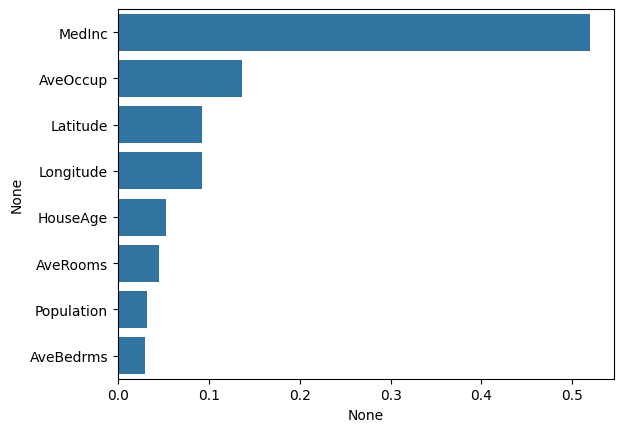

In [24]:
import seaborn as sns

rf = RandomForestRegressor(n_estimators = 1000, n_jobs = -1)
rf.fit(X_data, y_target)
feature_series = pd.Series(data = rf.feature_importances_,
                            index = X_data.columns)
feature_series = feature_series.sort_values(ascending = False)
sns.barplot(x = feature_series, y = feature_series.index)

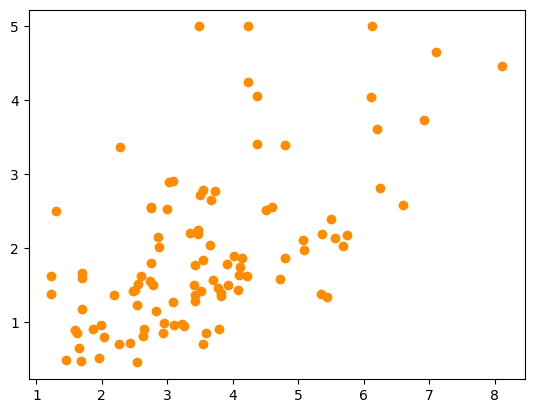

In [25]:
import matplotlib.pyplot as plt

df_sample = df[["MedInc", "PRICE"]]
df_sample = df_sample.sample(n = 100, random_state = 42)
plt.figure()
plt.scatter(df_sample.MedInc, df_sample.PRICE, c= "darkorange")

In [26]:
import numpy as np
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
dt1 = DecisionTreeRegressor(max_depth = 2)
dt2 = DecisionTreeRegressor(max_depth = 7)

X_test = np.arange(1.0, 10.0, 0.09).reshape(-1, 1)
X_feature = df_sample["MedInc"].values.reshape(-1, 1)
y_target = df_sample["PRICE"].values.reshape(-1, 1)

lr.fit(X_feature, y_target)
dt1.fit(X_feature, y_target)
dt2.fit(X_feature, y_target)

pred_lr = lr.predict(X_test)
pred_dt1 = dt1.predict(X_test)
pred_dt2 = dt2.predict(X_test)


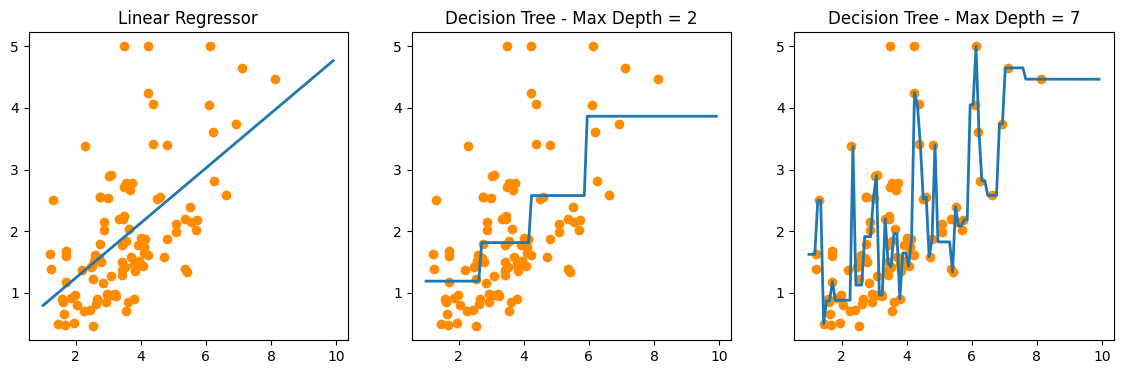

In [28]:
fig, (ax1, ax2, ax3) = plt.subplots(figsize = (14, 4), ncols = 3)
ax1.set_title("Linear Regressor")
ax1.scatter(df_sample.MedInc, df_sample.PRICE, c = "darkorange")
ax1.plot(X_test, pred_lr, label = "linear", linewidth = 2)

ax2.set_title("Decision Tree - Max Depth = 2")
ax2.scatter(df_sample.MedInc, df_sample.PRICE, c = "darkorange")
ax2.plot(X_test, pred_dt1, label = "max_depth:2", linewidth = 2)

ax3.set_title("Decision Tree - Max Depth = 7")
ax3.scatter(df_sample.MedInc, df_sample.PRICE, c = "darkorange")
ax3.plot(X_test, pred_dt2, label = "max_depth:7", linewidth = 2)